# Part 1: Dataset Explainer & Ground-Truth Citation Lineage

This section inspects and explains the **SNAP US Patent Citation Network** (`cit-Patents.txt`) alongside the accompanying NBER patent metadata (`pat63_99.tpt`).

### Pipeline Stages:
1. **Graph Topology Ingestion**: Load the directed network of patent citations where a directed edge $(u, v)$ signifies that patent $u$ cites prior art patent $v$.
2. **Metadata Ingestion & Caching**: Extract grant date, grant year, technological category, and subcategory from the SAS Transport (`.tpt`) file and cache as a fast binary pickle.
3. **Lineage Path Extraction**: Discover a verified $k$-hop backward citation chain where every intermediate patent has verified metadata.
4. **Lineage Visualization**: Render and display the chronological prior-art citation graph.


### 1.1 Imports & Environment Setup


In [1]:
import os
import sys
import pickle
import time
from collections import defaultdict, deque
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Ensure console and notebook output streams handle utf-8 cleanly
if sys.platform == "win32":
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass


### 1.2 Graph Topology and SAS Metadata Loaders
Functions to load the edge list into an adjacency list and parse/cache NBER SAS transport metadata.


In [2]:
# =====================================================================
# 1. LOAD GRAPH & METADATA
# =====================================================================
def load_graph(edge_file_path):
    print(f"Loading graph from '{edge_file_path}'...")
    t0 = time.time()
    adj = defaultdict(list)
    edge_count = 0
    with open(edge_file_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.startswith("#") or not line.strip():
                continue
            u, v = line.split()
            adj[int(u)].append(int(v))
            edge_count += 1
            if edge_count % 5_000_000 == 0:
                print(f"  Loaded {edge_count:,} edges...")
    print(f"Graph loaded: {edge_count:,} edges in {time.time() - t0:.2f}s.\n")
    return adj


def get_metadata(cache_path="meta_cache_v2.pkl", tpt_path="pat63_99.tpt"):
    if os.path.exists(cache_path):
        print(f"Loading cached metadata from '{cache_path}'...")
        with open(cache_path, "rb") as f:
            meta = pickle.load(f)
        print(f"Loaded {len(meta):,} metadata records.\n")
        return meta
    
    print(f"Cache not found. Reading .tpt file '{tpt_path}'...")
    meta = {}
    reader = pd.read_sas(tpt_path, format="xport", chunksize=250_000)
    for chunk in reader:
        chunk.columns = [col.lower() for col in chunk.columns]
        subset = chunk[["patent", "gdate", "gyear", "cat", "subcat"]].dropna(subset=["patent"])
        for row in subset.itertuples(index=False):
            try:
                pid = int(row.patent)
                gdate = int(row.gdate) if pd.notna(row.gdate) else 0
                gyear = int(row.gyear) if pd.notna(row.gyear) else 0
                meta[pid] = (gdate, gyear, int(row.cat) if pd.notna(row.cat) else 0, int(row.subcat) if pd.notna(row.subcat) else 0)
            except (ValueError, OverflowError):
                continue
    with open(cache_path, "wb") as f:
        pickle.dump(meta, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Loaded {len(meta):,} metadata records and cached to disk.\n")
    return meta


### 1.3 Verified Citation Lineage Subgraph Extraction
Extracts a verified multi-hop backbone citation chain where every intermediate patent has verified metadata.


In [3]:
# =====================================================================
# 2. EXTRACT A 100% VERIFIED GROUND-TRUTH CITATION LINEAGE
# =====================================================================
def find_verified_lineage_subgraph(adj, meta, target_hops=5):
    """
    Finds a verified linear backbone path of length target_hops (e.g. 5 steps),
    plus all genuine cross/skip citations between the nodes in that chain.
    """
    print(f"Searching for a verified lineage chain of length {target_hops}...")
    
    # Iterate through patents with high connectivity to find a rich lineage
    for start_node in adj:
        if start_node not in meta:
            continue
            
        # Run BFS to find a guaranteed node at exact depth = target_hops
        queue = deque([(start_node, [start_node])])
        visited = {start_node}
        
        while queue:
            curr, path = queue.popleft()
            
            if len(path) - 1 == target_hops and curr in meta:
                # Validate that all intermediate nodes have metadata
                if all(node in meta for node in path):
                    print(f"Verified chain found! Start: {start_node} -> Target: {curr}")
                    
                    # Extract any real cross/skip edges existing between these exact nodes
                    path_nodes_set = set(path)
                    all_subgraph_edges = []
                    for u in path:
                        for v in adj.get(u, []):
                            if v in path_nodes_set:
                                all_subgraph_edges.append((u, v))
                                
                    return path, all_subgraph_edges
                    
            if len(path) - 1 < target_hops:
                for neighbor in adj.get(curr, []):
                    if neighbor not in visited and neighbor in meta:
                        visited.add(neighbor)
                        queue.append((neighbor, path + [neighbor]))
                        
    return None, None


### 1.4 Citation Lineage Visualization Function
Configures the network visualization with dark aesthetic, chronological timeline positioning, and directed citation curves.


In [4]:
# =====================================================================
# 3. VISUALIZATION AND EXPORT
# =====================================================================
def plot_and_save_real_lineage(path, edges, meta, output_filename="real_citation_lineage.png"):
    print(f"Rendering verified citation graph for {len(path)} patents...")
    
    G = nx.DiGraph()
    G.add_edges_from(edges)
    
    # Node positioning: arrange strictly by timeline year on X-axis
    pos = {}
    years = [meta[n][1] for n in path]
    min_year, max_year = min(years), max(years)
    
    # Calculate horizontal layout with slight vertical staggering for readability
    for i, node in enumerate(path):
        year = meta[node][1]
        y_pos = 0.08 if i % 2 == 1 else -0.08
        pos[node] = (year, y_pos)
        
    fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)
    fig.patch.set_facecolor("#0f172a")  # Dark slate background
    ax.set_facecolor("#0f172a")

    # Header title & dataset subtitle
    ax.text(
        (min_year + max_year) / 2.0, 0.40,
        "CITATION LINEAGE ",
        color="#38bdf8", fontsize=13, fontweight="bold", ha="center"
    )
    ax.text(
        (min_year + max_year) / 2.0, 0.33,
        "Verified backward citation edges (Newer Patent ---> Older Cited Prior Art)",
        color="#94a3b8", fontsize=9.5, ha="center", style="italic"
    )

    # Timeline bar at bottom
    arrow_margin = 1
    ax.annotate(
        "", 
        xy=(max_year + 0.5, -0.38), 
        xytext=(min_year - 0.5, -0.38),
        arrowprops=dict(arrowstyle="->", color="#38bdf8", lw=1.6)
    )
    ax.text((min_year + max_year) / 2.0, -0.45, f"TIMELINE ({min_year} ---> {max_year})", color="#38bdf8", fontsize=9, fontweight="bold", ha="center")
    ax.text(min_year - 0.5, -0.45, "Older Cited Art", color="#94a3b8", fontsize=8, ha="left")
    ax.text(max_year + 0.5, -0.45, "Newer Invention", color="#94a3b8", fontsize=8, ha="right")

    # Draw directed backward edges
    nx.draw_networkx_edges(
        G, pos,
        edgelist=edges,
        edge_color="#fb7185",
        arrows=True,
        arrowstyle="-|>",
        arrowsize=14,
        connectionstyle="arc3,rad=0.18",
        width=1.6,
        alpha=0.85,
        ax=ax
    )

    # Edge labels
    for u, v in edges:
        x_m = (pos[u][0] + pos[v][0]) / 2.0
        y_m = (pos[u][1] + pos[v][1]) / 2.0 + 0.05
        ax.text(x_m, y_m, "cites", color="#f43f5e", fontsize=7.5, style="italic", ha="center")

    # Draw nodes
    nx.draw_networkx_nodes(
        G, pos,
        node_size=1800,
        node_color="#0284c7",
        edgecolors="#38bdf8",
        linewidths=1.4,
        ax=ax
    )

    # Label nodes with actual patent numbers and grant years
    labels = {
        node: f"US Pat {node}\n({meta[node][1]})\nCat: {meta[node][2]}"
        for node in path
    }
    nx.draw_networkx_labels(
        G, pos,
        labels=labels,
        font_size=7.5,
        font_color="#ffffff",
        font_weight="bold",
        ax=ax
    )

    # Bounds
    ax.set_xlim(min_year - 1.5, max_year + 1.5)
    ax.set_ylim(-0.55, 0.50)
    ax.axis("off")

    plt.tight_layout()
    plt.savefig(output_filename, facecolor=fig.get_facecolor(), bbox_inches="tight")
    # Added plt.show() to ensure inline display in Jupyter notebooks
    plt.show()
    plt.close(fig)
    print(f"[SAVED] {output_filename} successfully written to directory!")


### 1.5 Dataset Loading and Lineage Extraction Execution


In [5]:
# =====================================================================
# 4. MAIN EXECUTION: LOAD DATASET & EXTRACT LINEAGE
# =====================================================================
edge_file = "cit-Patents.txt"
cache_file = "meta_cache_v2.pkl"
tpt_file = "pat63_99.tpt"

# 1. Load actual dataset
graph = load_graph(edge_file)
meta = get_metadata(cache_path=cache_file, tpt_path=tpt_file)

# 2. Extract a real 5-hop path from the dataset
chain, edges = find_verified_lineage_subgraph(graph, meta, target_hops=5)

if chain:
    print("\nExtracted Verified Citation Chain:")
    for idx, pid in enumerate(chain):
        gdate, gyear, cat, subcat = meta[pid]
        print(f"  Step {idx}: US Patent {pid} (Year: {gyear}, Category: {cat}, Subcategory: {subcat})")
    print(f"Total subgraph citation edges: {len(edges)}")
else:
    print("No path of target length found.")


Loading graph from 'cit-Patents.txt'...
  Loaded 5,000,000 edges...
  Loaded 10,000,000 edges...
  Loaded 15,000,000 edges...
Graph loaded: 16,518,948 edges in 8.11s.

Loading cached metadata from 'meta_cache_v2.pkl'...
Loaded 2,923,922 metadata records.

Searching for a verified lineage chain of length 5...
Verified chain found! Start: 3866689 -> Target: 3075352

Extracted Verified Citation Chain:
  Step 0: US Patent 3866689 (Year: 1975, Category: 6, Subcategory: 64)
  Step 1: US Patent 4692121 (Year: 1987, Category: 4, Subcategory: 41)
  Step 2: US Patent 4579404 (Year: 1986, Category: 4, Subcategory: 41)
  Step 3: US Patent 4269466 (Year: 1981, Category: 4, Subcategory: 41)
  Step 4: US Patent 3859787 (Year: 1975, Category: 4, Subcategory: 45)
  Step 5: US Patent 3075352 (Year: 1963, Category: 4, Subcategory: 45)
Total subgraph citation edges: 5


## Figure: Verified Citation Lineage Graph
Cell break: Renders and displays the verified backward citation chain along the historical timeline.


Rendering verified citation graph for 6 patents...


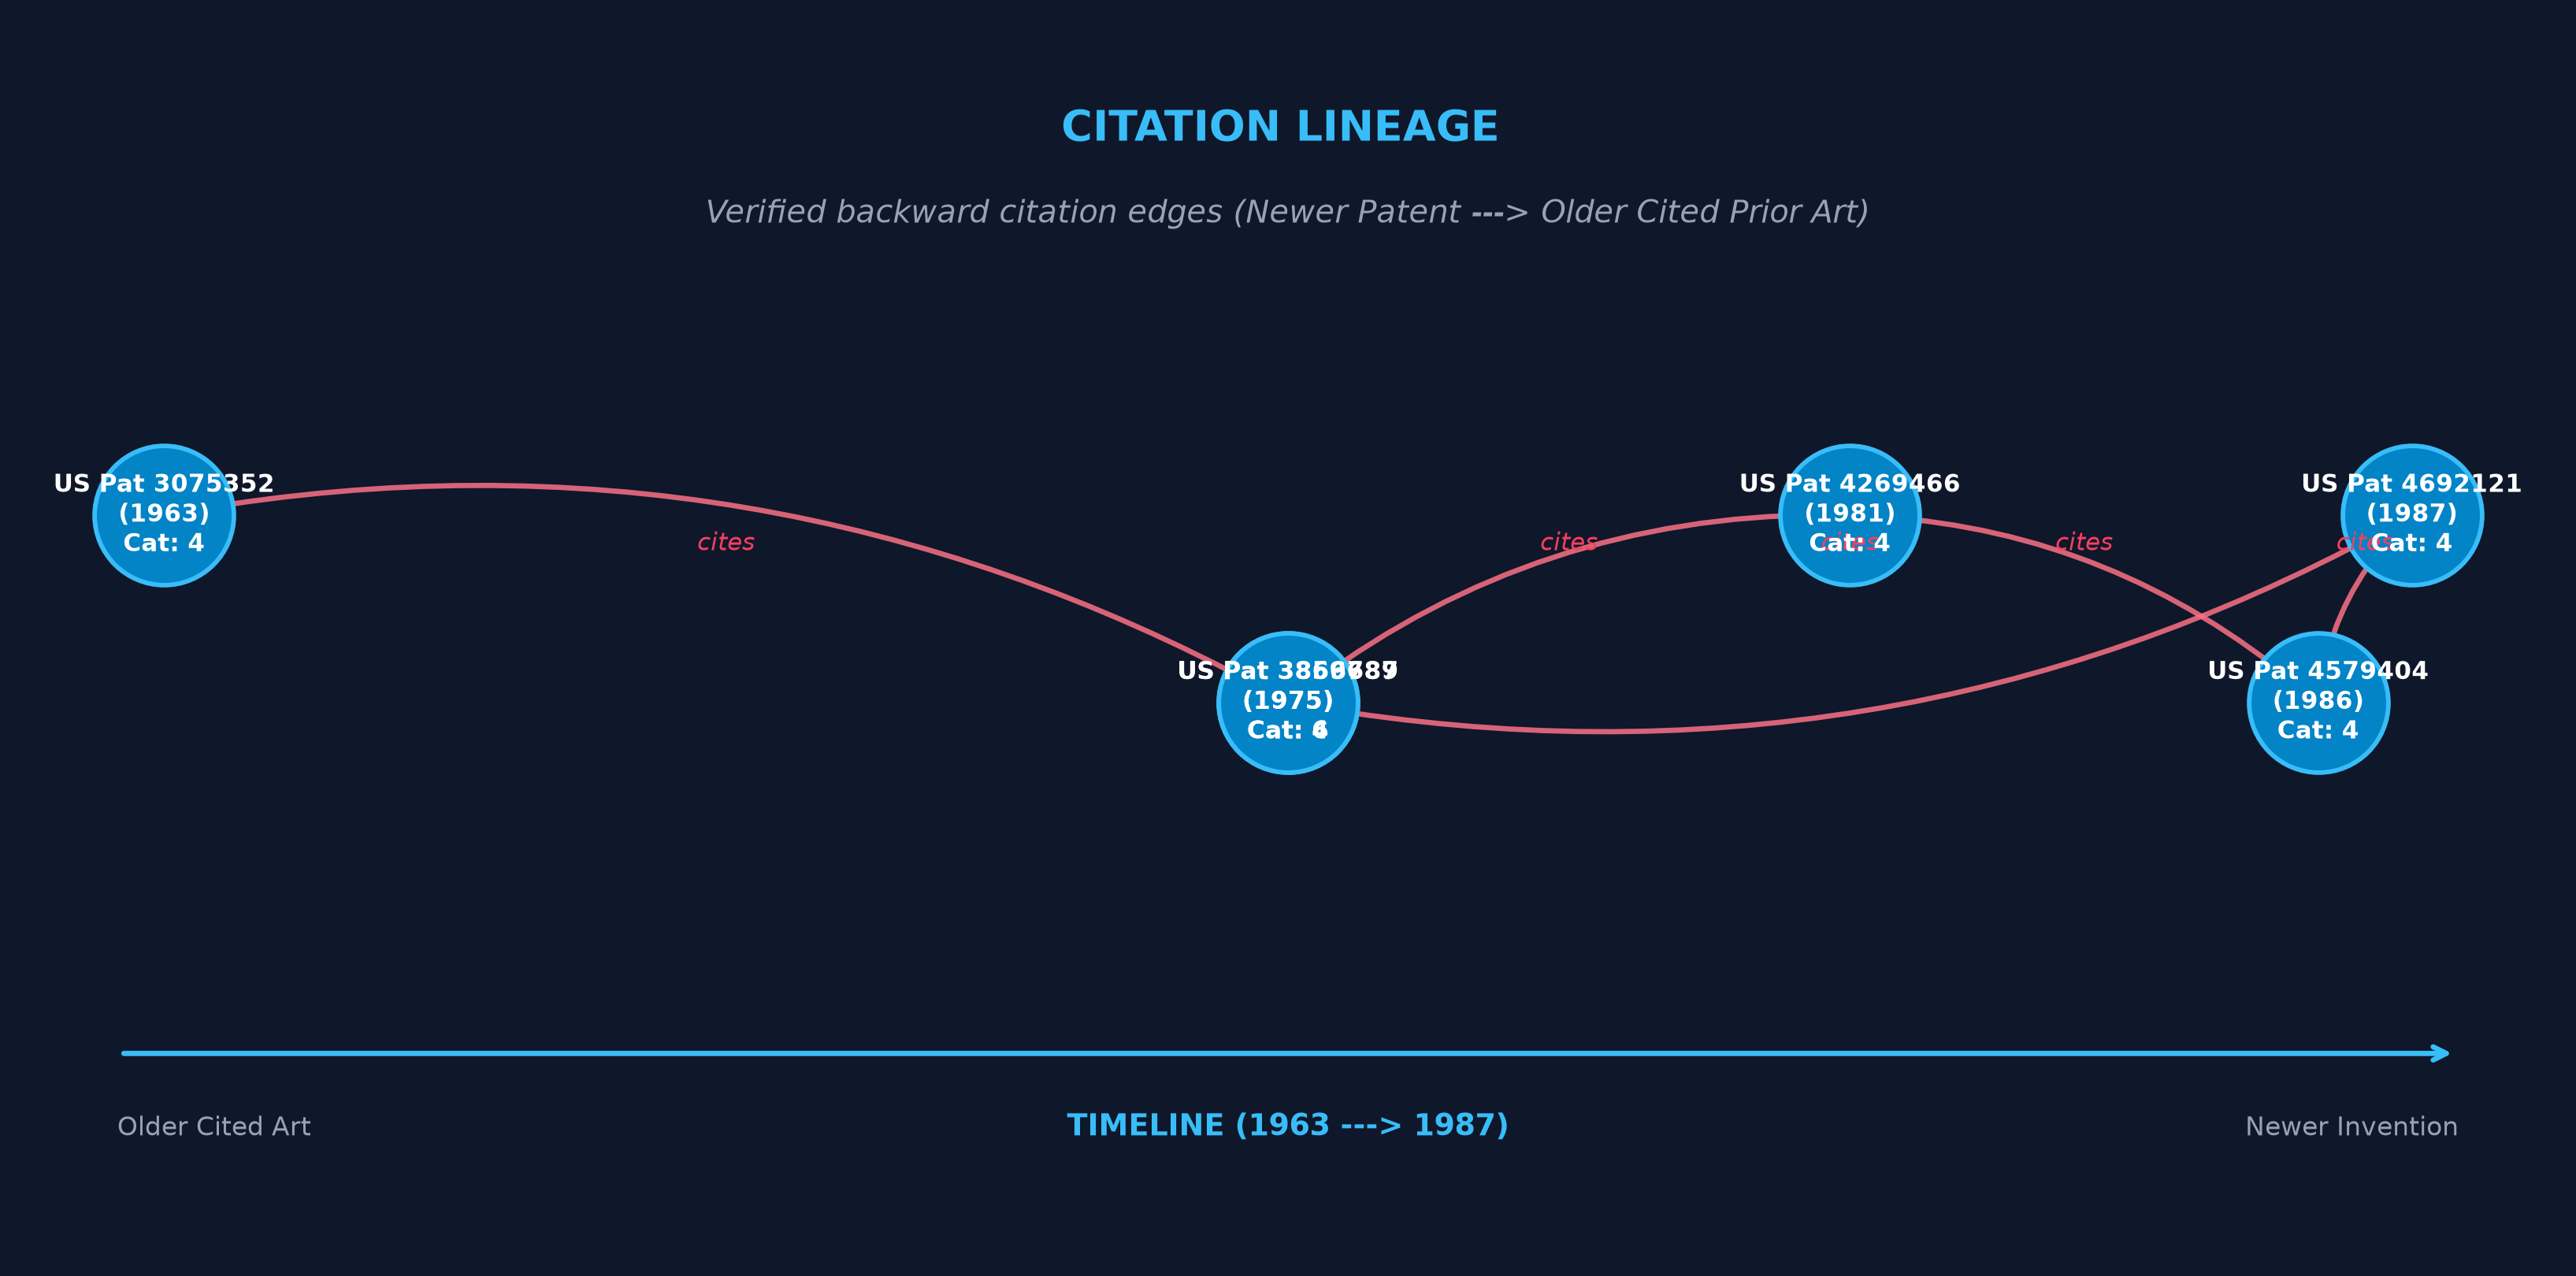

[SAVED] real_citation_lineage.png successfully written to directory!


In [6]:
# Render and show the verified citation lineage graph as cell output
if chain:
    plot_and_save_real_lineage(chain, edges, meta, output_filename="real_citation_lineage.png")
    plt.show()
else:
    print("Chain not found; skipping lineage graph rendering.")


# Part 2: Comparative Evaluation of Graph Search Algorithms on the SNAP Patent Citation Network

Search strategies evaluated:
1. **Breadth-First Search (BFS)**: Optimal, complete uninformed graph traversal.
2. **Iterative Deepening Search (IDS)**: Depth-first iterative deepening providing optimal paths in linear $O(bd)$ memory.
3. **A* Search (Coarse Heuristic - $h_1$)**: Directed A* search pruning backward searches violating temporal causality based on grant year.
4. **A* Search (Fine-Grained Heuristic - $h_2$)**: Directed A* search incorporating calendar-day precision and technological subcategory tie-breakers.

Generates benchmark metrics across target hop depths $d \in [2, 10]$ and renders all publication figures.


### 2.1 Solution Configuration & Plot Aesthetics


In [7]:
import heapq
import random
import math

# Increase recursion depth for deep search branches in IDS
sys.setrecursionlimit(50000)

# Configure plot aesthetics
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "lines.linewidth": 2.0,
    "lines.markersize": 6,
    "grid.alpha": 0.4,
    "grid.linestyle": "--"
})


### 2.2 SAS Metadata Loader with Chunking and Caching


In [8]:
def load_metadata_tpt(tpt_file_path):
    print(f"Reading SAS transport file '{tpt_file_path}'...")
    t0 = time.time()
    meta = {}
    chunk_size = 250_000
    
    reader = pd.read_sas(tpt_file_path, format='xport', chunksize=chunk_size)
    total_rows = 0
    
    for chunk in reader:
        chunk.columns = [col.lower() for col in chunk.columns]
        cols_needed = ['patent', 'gdate', 'gyear', 'cat', 'subcat']
        subset = chunk[cols_needed].dropna(subset=['patent'])
        
        for row in subset.itertuples(index=False):
            try:
                pid = int(row.patent)
                gdate = int(row.gdate) if pd.notna(row.gdate) else 0
                gyear = int(row.gyear) if pd.notna(row.gyear) else 0
                cat = int(row.cat) if pd.notna(row.cat) else 0
                subcat = int(row.subcat) if pd.notna(row.subcat) else 0
                meta[pid] = (gdate, gyear, cat, subcat)
            except (ValueError, OverflowError):
                continue
                
        total_rows += len(chunk)
        print(f"  Processed {total_rows:,} rows from .tpt...")

    print(f"Loaded metadata for {len(meta):,} patents in {time.time() - t0:.2f}s.\n")
    return meta


def get_cached_metadata(tpt_path, cache_path="meta_cache_v2.pkl"):
    if os.path.exists(cache_path):
        print(f"Loading cached metadata from '{cache_path}'...")
        t0 = time.time()
        with open(cache_path, 'rb') as f:
            meta = pickle.load(f)
        print(f"Cache loaded for {len(meta):,} patents in {time.time() - t0:.2f}s!\n")
        return meta
    else:
        meta = load_metadata_tpt(tpt_path)
        print(f"Writing parsed metadata to cache '{cache_path}'...")
        with open(cache_path, 'wb') as f:
            pickle.dump(meta, f, protocol=pickle.HIGHEST_PROTOCOL)
        print("Cache saved successfully.\n")
        return meta


### 2.3 Heuristic Formulations ($h_1$ and $h_2$)
- **$h_1$ (Coarse Year)**: Measures grant year temporal difference normalized by maximum expected lag ($25$ years). Assigns $\infty$ to acausal backward steps.
- **$h_2$ (Fine Date + Category)**: Measures exact calendar grant date lag over $9,131$ days with technological class tie-breaking.


In [9]:
def h1_coarse_year(node, target, meta, max_lag_years=25.0):
    node_data = meta.get(node)
    target_data = meta.get(target)
    if not node_data or not target_data:
        return 0.0

    _, nyear, _, _ = node_data
    _, tyear, _, _ = target_data

    year_diff = nyear - tyear
    if year_diff < 0:
        return float('inf')

    return year_diff / max_lag_years


def h2_fine_date(node, target, meta, max_lag_days=9131.0):
    node_data = meta.get(node)
    target_data = meta.get(target)
    if not node_data or not target_data:
        return 0.0

    ndate, _, ncat, nsubcat = node_data
    tdate, _, tcat, tsubcat = target_data

    date_diff = ndate - tdate
    if date_diff < 0:
        return float('inf')

    h_time = date_diff / max_lag_days

    tie_breaker = 0.0
    if nsubcat != tsubcat or nsubcat == 0:
        tie_breaker += 0.005
    if ncat != tcat or ncat == 0:
        tie_breaker += 0.004

    return h_time + tie_breaker


### 2.4 Search Algorithm Implementations with Frontier Profiling
Includes BFS, IDS (DLS with stack tracking), and priority queue A* search.


In [10]:
def bfs_shortest_path(adj, start_node, target_node):
    t0 = time.time()
    if start_node == target_node:
        return [start_node], 0, 1, time.time() - t0

    queue = deque([start_node])
    parent = {start_node: None}
    nodes_expanded = 0
    max_frontier = len(queue)

    while queue:
        curr = queue.popleft()
        nodes_expanded += 1

        for neighbor in adj.get(curr, []):
            if neighbor not in parent:
                parent[neighbor] = curr
                
                if neighbor == target_node:
                    path = []
                    step = target_node
                    while step is not None:
                        path.append(step)
                        step = parent[step]
                    path.reverse()
                    return path, nodes_expanded, max_frontier, time.time() - t0
                
                queue.append(neighbor)
                if len(queue) > max_frontier:
                    max_frontier = len(queue)

    return None, nodes_expanded, max_frontier, time.time() - t0


def dls(adj, curr_node, target_node, limit, current_depth, visited_depth, path, counter, max_stack):
    counter[0] += 1
    if current_depth > max_stack[0]:
        max_stack[0] = current_depth

    if curr_node == target_node:
        return True
    if current_depth >= limit:
        return False

    for neighbor in adj.get(curr_node, []):
        if neighbor not in visited_depth or visited_depth[neighbor] > current_depth + 1:
            visited_depth[neighbor] = current_depth + 1
            path.append(neighbor)
            
            if dls(adj, neighbor, target_node, limit, current_depth + 1, visited_depth, path, counter, max_stack):
                return True
                
            path.pop()
    return False


def ids_shortest_path(adj, start_node, target_node, max_depth=15):
    t0 = time.time()
    total_expanded = [0]
    peak_stack = [0]
    
    for limit in range(max_depth + 1):
        visited_depth = {start_node: 0}
        path = [start_node]
        if dls(adj, start_node, target_node, limit, 0, visited_depth, path, total_expanded, peak_stack):
            return path, total_expanded[0], peak_stack[0], time.time() - t0
            
    return None, total_expanded[0], peak_stack[0], time.time() - t0


def astar_search(adj, start_node, target_node, meta, heuristic_fn):
    t0 = time.time()
    if start_node == target_node:
        return [start_node], 0, 1, time.time() - t0

    counter = 0
    open_heap = []
    
    g_score = {start_node: 0}
    parent = {start_node: None}
    
    h_start = heuristic_fn(start_node, target_node, meta)
    f_start = 0 + h_start
    heapq.heappush(open_heap, (f_start, counter, start_node))
    
    nodes_expanded = 0
    max_frontier = len(open_heap)
    closed_set = set()

    while open_heap:
        f_curr, _, curr = heapq.heappop(open_heap)

        if curr in closed_set:
            continue
        closed_set.add(curr)
        nodes_expanded += 1

        if curr == target_node:
            path = []
            step = target_node
            while step is not None:
                path.append(step)
                step = parent[step]
            path.reverse()
            return path, nodes_expanded, max_frontier, time.time() - t0

        curr_g = g_score[curr]

        for neighbor in adj.get(curr, []):
            tentative_g = curr_g + 1

            if neighbor not in g_score or tentative_g < g_score[neighbor]:
                g_score[neighbor] = tentative_g
                parent[neighbor] = curr
                
                h_val = heuristic_fn(neighbor, target_node, meta)
                if h_val == float('inf'):
                    continue
                
                f_val = tentative_g + h_val
                counter += 1
                heapq.heappush(open_heap, (f_val, counter, neighbor))
                if len(open_heap) > max_frontier:
                    max_frontier = len(open_heap)

    return None, nodes_expanded, max_frontier, time.time() - t0


### 2.5 Pair Sampling Utilities
Generates $k$ random patent source-target pairs separated by exactly `target_hops` steps.


In [11]:
def find_k_multi_hop_pairs(adj, meta, target_hops, k=1, seed=42):
    random.seed(seed)
    candidates = [p for p in adj.keys() if p in meta]
    random.shuffle(candidates)
    
    pairs = []
    for start in candidates:
        visited = {start: 0}
        queue = deque([start])
        found_target = None

        while queue:
            curr = queue.popleft()
            dist = visited[curr]

            if dist == target_hops and curr in meta:
                found_target = curr
                break

            if dist < target_hops:
                for nxt in adj.get(curr, []):
                    if nxt not in visited:
                        visited[nxt] = dist + 1
                        queue.append(nxt)
                        
        if found_target:
            pairs.append((start, found_target))
            if len(pairs) == k:
                break
                
    return pairs


### 2.6 Data Preparation & Evaluation Hop Range


In [12]:
# Re-use already loaded graph & meta or load if not yet initialized
if 'graph' not in locals():
    edge_file = "cit-Patents.txt"
    graph = load_graph(edge_file)

if 'meta' not in locals():
    tpt_file = "pat63_99.tpt"
    meta = get_cached_metadata(tpt_file, cache_path="meta_cache_v2.pkl")

evaluation_hops = [2, 3, 4, 5, 6, 7, 8, 9, 10]
print(f"Configured evaluation hop depths: {evaluation_hops}")


Configured evaluation hop depths: [2, 3, 4, 5, 6, 7, 8, 9, 10]


### 2.7 Part 1: Single-Sample Detailed Breakdown Across All Target Hops ($d = 2 \dots 10$)


In [13]:
print("=" * 115)
print("PART 1: SINGLE-SAMPLE DETAILED BREAKDOWN ACROSS DEPTHS (2 to 10)")
print("=" * 115)
print(f"{'TARGET HOPS':<12} {'ALGORITHM':<12} {'START':<10} {'TARGET':<10} {'HOPS':<6} {'EXPANDED':<12} {'PEAK FRONT':<12} {'TIME (s)':<10}")
print("-" * 115)

for depth in evaluation_hops:
    pairs = find_k_multi_hop_pairs(graph, meta, target_hops=depth, k=1, seed=100 + depth)
    if not pairs:
        print(f"Could not find a valid pair for depth {depth}.")
        continue
    
    start_node, target_node = pairs[0]

    b_path, b_exp, b_mem, b_time = bfs_shortest_path(graph, start_node, target_node)
    b_hops = (len(b_path) - 1) if b_path else "N/A"
    print(f"{depth:<12} {'BFS':<12} {start_node:<10} {target_node:<10} {str(b_hops):<6} {b_exp:<12,} {b_mem:<12,} {b_time:<10.4f}")

    i_path, i_exp, i_mem, i_time = ids_shortest_path(graph, start_node, target_node, max_depth=depth + 4)
    i_hops = (len(i_path) - 1) if i_path else "N/A"
    print(f"{depth:<12} {'IDS':<12} {start_node:<10} {target_node:<10} {str(i_hops):<6} {i_exp:<12,} {i_mem:<12,} {i_time:<10.4f}")

    ac_path, ac_exp, ac_mem, ac_time = astar_search(graph, start_node, target_node, meta, h1_coarse_year)
    ac_hops = (len(ac_path) - 1) if ac_path else "N/A"
    print(f"{depth:<12} {'A*(Coarse)':<12} {start_node:<10} {target_node:<10} {str(ac_hops):<6} {ac_exp:<12,} {ac_mem:<12,} {ac_time:<10.4f}")

    af_path, af_exp, af_mem, af_time = astar_search(graph, start_node, target_node, meta, h2_fine_date)
    af_hops = (len(af_path) - 1) if af_path else "N/A"
    print(f"{depth:<12} {'A*(Fine)':<12} {start_node:<10} {target_node:<10} {str(af_hops):<6} {af_exp:<12,} {af_mem:<12,} {af_time:<10.4f}")

    print("-" * 115)


PART 1: SINGLE-SAMPLE DETAILED BREAKDOWN ACROSS DEPTHS (2 to 10)
TARGET HOPS  ALGORITHM    START      TARGET     HOPS   EXPANDED     PEAK FRONT   TIME (s)  
-------------------------------------------------------------------------------------------------------------------
2            BFS          5209845    3539480    2      2            4            0.0000    
2            IDS          5209845    3539480    2      10           2            0.0000    
2            A*(Coarse)   5209845    3539480    2      7            20           0.0001    
2            A*(Fine)     5209845    3539480    2      7            20           0.0000    
-------------------------------------------------------------------------------------------------------------------
3            BFS          5538930    3519553    3      8            4            0.0000    
3            IDS          5538930    3519553    3      23           3            0.0000    
3            A*(Coarse)   5538930    3519553    3      10  

### 2.8 Part 2: Statistically Aggregated Benchmark Across $K = 10$ Samples per Depth


In [14]:
K_SAMPLES = 10
algorithms = ["BFS", "IDS", "A*(Coarse)", "A*(Fine)"]
summary_data = []

print("=" * 115)
print(f"PART 2: STATISTICAL BENCHMARK (AGGREGATED OVER K = {K_SAMPLES} SAMPLES PER DEPTH)")
print("=" * 115)

for depth in evaluation_hops:
    print(f"Sampling {K_SAMPLES} test pairs for depth {depth}...")
    pairs = find_k_multi_hop_pairs(graph, meta, target_hops=depth, k=K_SAMPLES, seed=2000 + depth)
    
    if len(pairs) < K_SAMPLES:
        print(f"  Note: Retrieved {len(pairs)}/{K_SAMPLES} pairs for depth {depth}.")

    metrics = {algo: {'exp': [], 'mem': [], 'time': []} for algo in algorithms}

    for start, target in pairs:
        _, b_exp, b_mem, b_time = bfs_shortest_path(graph, start, target)
        metrics["BFS"]['exp'].append(b_exp)
        metrics["BFS"]['mem'].append(b_mem)
        metrics["BFS"]['time'].append(b_time)

        _, i_exp, i_mem, i_time = ids_shortest_path(graph, start, target, max_depth=depth + 4)
        metrics["IDS"]['exp'].append(i_exp)
        metrics["IDS"]['mem'].append(i_mem)
        metrics["IDS"]['time'].append(i_time)

        _, ac_exp, ac_mem, ac_time = astar_search(graph, start, target, meta, h1_coarse_year)
        metrics["A*(Coarse)"]['exp'].append(ac_exp)
        metrics["A*(Coarse)"]['mem'].append(ac_mem)
        metrics["A*(Coarse)"]['time'].append(ac_time)

        _, af_exp, af_mem, af_time = astar_search(graph, start, target, meta, h2_fine_date)
        metrics["A*(Fine)"]['exp'].append(af_exp)
        metrics["A*(Fine)"]['mem'].append(af_mem)
        metrics["A*(Fine)"]['time'].append(af_time)

    for algo in algorithms:
        exp_list = metrics[algo]['exp']
        mem_list = metrics[algo]['mem']
        time_list = metrics[algo]['time']

        mean_exp = sum(exp_list) / len(exp_list)
        std_exp = math.sqrt(sum((x - mean_exp)**2 for x in exp_list) / len(exp_list)) if len(exp_list) > 1 else 0.0

        mean_mem = sum(mem_list) / len(mem_list)
        std_mem = math.sqrt(sum((x - mean_mem)**2 for x in mem_list) / len(mem_list)) if len(mem_list) > 1 else 0.0

        mean_time = sum(time_list) / len(time_list)
        std_time = math.sqrt(sum((x - mean_time)**2 for x in time_list) / len(time_list)) if len(time_list) > 1 else 0.0

        summary_data.append({
            "Depth": depth,
            "Algorithm": algo,
            "Mean_Expanded": mean_exp,
            "Std_Expanded": std_exp,
            "Mean_Peak_Frontier": mean_mem,
            "Std_Peak_Frontier": std_mem,
            "Mean_Time_ms": mean_time * 1000.0,
            "Std_Time_ms": std_time * 1000.0
        })

df_summary = pd.DataFrame(summary_data)

print("\n" + "=" * 115)
print("CONFERENCE BENCHMARK SUMMARY (AGGREGATED OVER K SAMPLES)")
print("=" * 115)
print(f"{'DEPTH':<6} {'ALGORITHM':<12} {'NODES EXPANDED (Mean ± Std)':<30} {'PEAK FRONTIER':<20} {'TIME ms (Mean ± Std)'}")
print("-" * 115)

for _, row in df_summary.iterrows():
    exp_str = f"{row['Mean_Expanded']:,.1f} ± {row['Std_Expanded']:,.1f}"
    mem_str = f"{row['Mean_Peak_Frontier']:,.1f} ± {row['Std_Peak_Frontier']:,.1f}"
    time_str = f"{row['Mean_Time_ms']:.2f} ± {row['Std_Time_ms']:.2f}"
    print(f"{int(row['Depth']):<6} {row['Algorithm']:<12} {exp_str:<30} {mem_str:<20} {time_str}")

print("=" * 115)

output_csv = "search_benchmark_results.csv"
df_summary.to_csv(output_csv, index=False)
print(f"\nAggregated experimental data saved to '{output_csv}'.")


PART 2: STATISTICAL BENCHMARK (AGGREGATED OVER K = 10 SAMPLES PER DEPTH)
Sampling 10 test pairs for depth 2...
Sampling 10 test pairs for depth 3...
Sampling 10 test pairs for depth 4...
Sampling 10 test pairs for depth 5...
Sampling 10 test pairs for depth 6...
Sampling 10 test pairs for depth 7...
Sampling 10 test pairs for depth 8...
Sampling 10 test pairs for depth 9...
Sampling 10 test pairs for depth 10...

CONFERENCE BENCHMARK SUMMARY (AGGREGATED OVER K SAMPLES)
DEPTH  ALGORITHM    NODES EXPANDED (Mean ± Std)    PEAK FRONTIER        TIME ms (Mean ± Std)
-------------------------------------------------------------------------------------------------------------------
2      BFS          5.3 ± 4.1                      10.5 ± 8.9           0.01 ± 0.01
2      IDS          19.7 ± 10.8                    2.0 ± 0.0            0.01 ± 0.01
2      A*(Coarse)   11.2 ± 6.3                     39.5 ± 43.7          0.07 ± 0.06
2      A*(Fine)     10.9 ± 6.3                     37.9 ± 41.2   

### 2.9 Visualization Aesthetics & Color Palette Configuration


In [15]:
algo_styles = {
    "BFS": {"color": "#1f77b4", "marker": "o", "label": "BFS"},
    "IDS": {"color": "#d62728", "marker": "s", "label": "IDS"},
    "A*(Coarse)": {"color": "#ff7f0e", "marker": "^", "label": "A* (Coarse - $h_1$)"},
    "A*(Fine)": {"color": "#2ca02c", "marker": "D", "label": "A* (Fine - $h_2$)"}
}
algos = ["BFS", "IDS", "A*(Coarse)", "A*(Fine)"]


## Figure 1: State Space Exploration (Nodes Expanded vs. Depth)
Cell break: Plots and displays search tree expansion across algorithms on a logarithmic scale with standard deviation error shading.


[SAVED] fig1_nodes_expanded.png


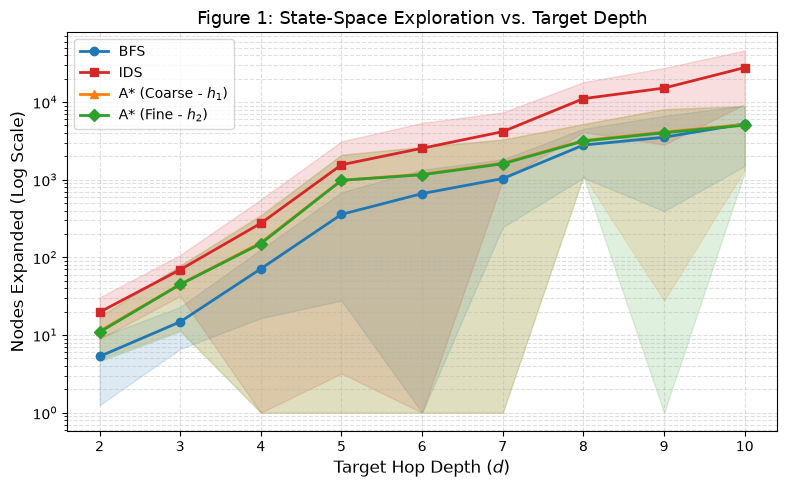

In [16]:
# --- FIGURE 1: State Space Exploration (Nodes Expanded vs. Depth) ---
fig1, ax1 = plt.subplots(figsize=(8, 5))
for algo in algos:
    sub = df_summary[df_summary["Algorithm"] == algo]
    ax1.plot(
        sub["Depth"],
        sub["Mean_Expanded"],
        color=algo_styles[algo]["color"],
        marker=algo_styles[algo]["marker"],
        label=algo_styles[algo]["label"]
    )
    lower_bound = (sub["Mean_Expanded"] - sub["Std_Expanded"]).clip(lower=1)
    upper_bound = sub["Mean_Expanded"] + sub["Std_Expanded"]
    ax1.fill_between(sub["Depth"], lower_bound, upper_bound, color=algo_styles[algo]["color"], alpha=0.15)

ax1.set_yscale("log")
ax1.set_xlabel("Target Hop Depth ($d$)")
ax1.set_ylabel("Nodes Expanded (Log Scale)")
ax1.set_title("Figure 1: State-Space Exploration vs. Target Depth")
ax1.grid(True, which="both")
ax1.legend(loc="upper left")
fig1.tight_layout()
fig1.savefig("fig1_nodes_expanded.png", dpi=300, bbox_inches="tight")
print("[SAVED] fig1_nodes_expanded.png")

# Show figure inline as cell output
plt.show()
plt.close(fig1)


## Figure 2: Wall-Clock Latency (Runtime in Milliseconds)
Cell break: Plots and displays search latency in milliseconds as depth increases from 2 to 10.


[SAVED] fig2_runtime_latency.png


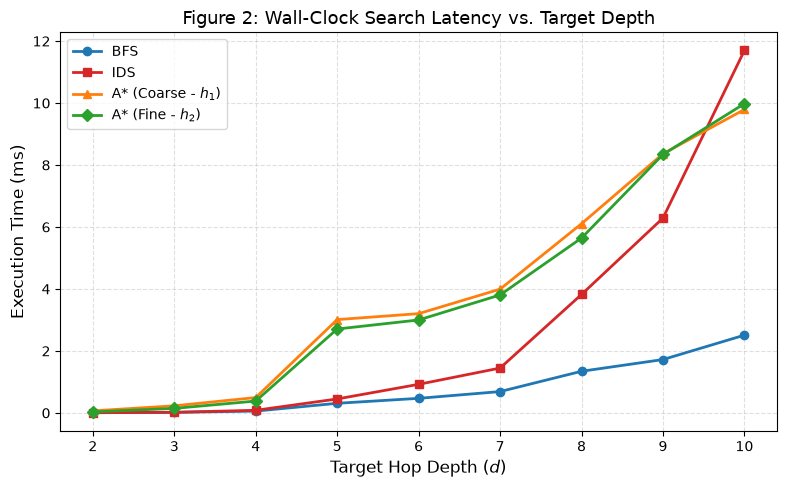

In [17]:
# --- FIGURE 2: Wall-Clock Latency (Runtime in Milliseconds) ---
fig2, ax2 = plt.subplots(figsize=(8, 5))
for algo in algos:
    sub = df_summary[df_summary["Algorithm"] == algo]
    ax2.plot(
        sub["Depth"],
        sub["Mean_Time_ms"],
        color=algo_styles[algo]["color"],
        marker=algo_styles[algo]["marker"],
        label=algo_styles[algo]["label"]
    )

ax2.set_xlabel("Target Hop Depth ($d$)")
ax2.set_ylabel("Execution Time (ms)")
ax2.set_title("Figure 2: Wall-Clock Search Latency vs. Target Depth")
ax2.grid(True)
ax2.legend(loc="upper left")
fig2.tight_layout()
fig2.savefig("fig2_runtime_latency.png", dpi=300, bbox_inches="tight")
print("[SAVED] fig2_runtime_latency.png")

# Show figure inline as cell output
plt.show()
plt.close(fig2)


## Figure 3: Heuristic Dominance Study (A* Fine vs. A* Coarse)
Cell break: Plots and displays the net pruning gain $(h_1 - h_2)$ achieved by incorporating exact calendar dates and technological category tie-breakers.


[SAVED] fig3_heuristic_dominance.png


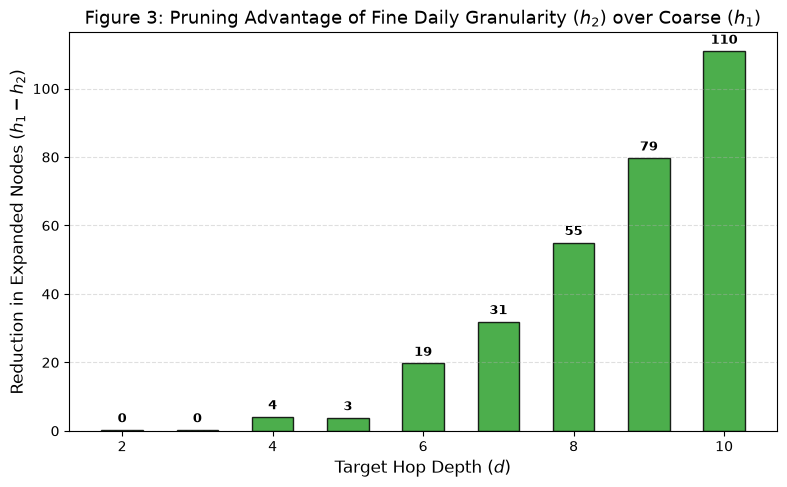

In [18]:
# --- FIGURE 3: Heuristic Dominance Study (A* Fine vs. A* Coarse) ---
fig3, ax3 = plt.subplots(figsize=(8, 5))
ac_sub = df_summary[df_summary["Algorithm"] == "A*(Coarse)"]
af_sub = df_summary[df_summary["Algorithm"] == "A*(Fine)"]

pruning_gain = ac_sub["Mean_Expanded"].values - af_sub["Mean_Expanded"].values
depths = ac_sub["Depth"].values

ax3.bar(
    depths,
    pruning_gain,
    color="#2ca02c",
    edgecolor="black",
    width=0.55,
    alpha=0.85
)

ax3.set_xlabel("Target Hop Depth ($d$)")
ax3.set_ylabel("Reduction in Expanded Nodes ($h_1 - h_2$)")
ax3.set_title("Figure 3: Pruning Advantage of Fine Daily Granularity ($h_2$) over Coarse ($h_1$)")
ax3.grid(True, axis="y")
max_val = max(pruning_gain) if len(pruning_gain) > 0 and max(pruning_gain) > 0 else 1.0
for x, y in zip(depths, pruning_gain):
    ax3.text(x, y + (max_val * 0.02), f"{int(y):,}", ha="center", fontsize=9, fontweight="bold")

fig3.tight_layout()
fig3.savefig("fig3_heuristic_dominance.png", dpi=300, bbox_inches="tight")
print("[SAVED] fig3_heuristic_dominance.png")

# Show figure inline as cell output
plt.show()
plt.close(fig3)


## Figure 4: Algorithmic Throughput (Nodes Processed per Millisecond)
Cell break: Plots and displays computational throughput (expansion speed) across search strategies.


[SAVED] fig4_throughput_efficiency.png


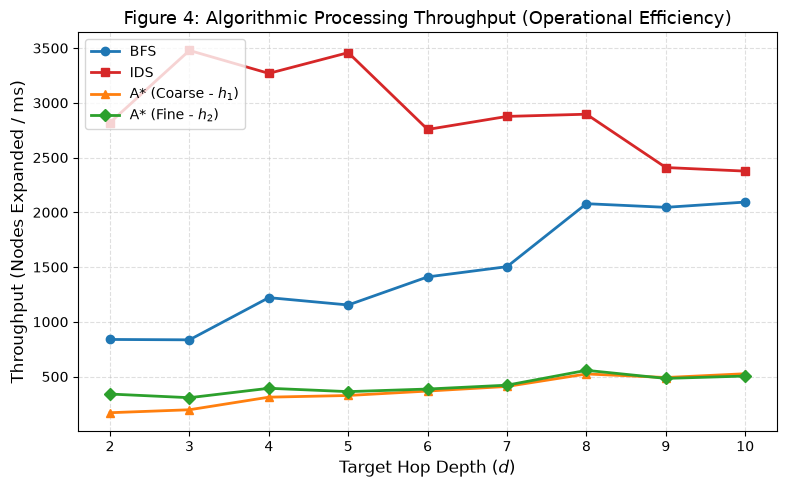

In [19]:
# --- FIGURE 4: Algorithmic Throughput (Nodes Processed per Millisecond) ---
fig4, ax4 = plt.subplots(figsize=(8, 5))
for algo in algos:
    sub = df_summary[df_summary["Algorithm"] == algo]
    exp_vals = sub["Mean_Expanded"].values
    time_vals = sub["Mean_Time_ms"].values
    throughput = [
        (e / t) if t > 0 else 0.0 for e, t in zip(exp_vals, time_vals)
    ]
    ax4.plot(
        sub["Depth"],
        throughput,
        color=algo_styles[algo]["color"],
        marker=algo_styles[algo]["marker"],
        label=algo_styles[algo]["label"]
    )

ax4.set_xlabel("Target Hop Depth ($d$)")
ax4.set_ylabel("Throughput (Nodes Expanded / ms)")
ax4.set_title("Figure 4: Algorithmic Processing Throughput (Operational Efficiency)")
ax4.grid(True)
ax4.legend(loc="upper left")
fig4.tight_layout()
fig4.savefig("fig4_throughput_efficiency.png", dpi=300, bbox_inches="tight")
print("[SAVED] fig4_throughput_efficiency.png")

# Show figure inline as cell output
plt.show()
plt.close(fig4)
